# 02: Repeat-purchase prediction with clustering and t-SNE

Can similar purchase patterns predict whether a customer buys again within **90 days**?
Each point is a **purchase occasion**, not a unique customer. The same customer may
appear in multiple chronological blocks, reflecting prediction for future purchases.

K-means learns groups without using outcomes. The training repeat rate in a group
then becomes its predicted probability. This label-to-probability step makes the
complete predictor supervised, although its clustering geometry is unsupervised.

We choose the cluster count using development cross-validation, compare with the
always-return baseline and the configured supervised classifier, and assess the
chosen model on the reserved holdout. t-SNE visualizes development data only;
it never supplies features or predictions. This experiment does not change saved
production models or generate a Kaggle submission.

In [1]:
from pathlib import Path
import copy
import sys

# Run from either the repository root or notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "config.yaml").exists():
    ROOT = ROOT.parent
assert (ROOT / "config.yaml").exists(), "Launch from the repository root or notebooks/."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.manifold import TSNE
from sklearn.metrics import ConfusionMatrixDisplay, silhouette_score
from sklearn.pipeline import Pipeline

from src.cleaning import drop_empty_rows
from src.clustering import ClusterClassifier
from src.data import load_config, load_data
from src.evaluate import TimeCalendarSplit, cross_validate_pipeline, score_model, split_holdout
from src.features import prepare, split_features_target
from src.model import FLOOR, build_pipeline
from src.preprocessing import build_preprocessor

config = load_config(str(ROOT / "config.yaml"), str(ROOT / "diagnosis.yaml"))
# Resolve data paths without changing the process working directory or config.yaml.
for name in ("train", "clients"):
    config["paths"][name] = str(ROOT / config["paths"][name])
SEED = config["seed"]
CLUSTER_COUNTS = [2, 3, 5, 8, 10]
METRICS = ["f1", "precision", "recall", "roc_auc", "average_precision"]
settings = {**config["classification"], "metrics": METRICS, "selection_metric": "f1"}
THRESHOLD = settings["threshold"]
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110


## 1. Prepare purchase-time features and chronological splits

Reuse production cleaning and feature construction. The latest configured fraction
is the holdout; a 90-day embargo separates its start from development training.
All candidate fits use the same gapped development folds. Neither the holdout nor
`test.csv` contributes to preprocessing, cluster selection, or visualization.

Both future targets, identifiers, purchase date, and random noise are excluded
from input features. Labels are retained separately for scoring and cluster rates.

In [2]:
raw, clients = load_data(config, "train")
excluded = config["id_cols"] + list(config["targets"].values())
feature_columns = [c for c in raw.columns if c not in excluded]
rows = prepare(drop_empty_rows(raw, feature_columns), clients, config)
validation = config["validation"]
dev, holdout = split_holdout(rows, validation["date_col"],
                             validation["holdout_fraction"], validation["gap_days"])
X_dev, y_dev = split_features_target(dev, config, "classification")
X_holdout, y_holdout = split_features_target(holdout, config, "classification")
forbidden = set(excluded + config["drop_columns"] + ["purchase_date", "random_noise"])
assert forbidden.isdisjoint(X_dev.columns)
assert forbidden.isdisjoint(X_holdout.columns)
cv = TimeCalendarSplit(dev[validation["date_col"]], validation["n_splits"], validation["gap_days"])
fold_description = []
for fold, (train_idx, val_idx) in enumerate(cv.split(X_dev), start=1):
    assert len(train_idx) >= max(CLUSTER_COUNTS), "Too few training rows for the requested cluster counts."
    train_end = pd.to_datetime(dev.iloc[train_idx][validation["date_col"]]).max()
    val_start = pd.to_datetime(dev.iloc[val_idx][validation["date_col"]]).min()
    assert train_end < val_start - pd.Timedelta(days=validation["gap_days"])
    fold_description.append({"fold": fold, "training_rows": len(train_idx),
                             "validation_rows": len(val_idx), "training_end": train_end,
                             "validation_start": val_start})
assert pd.to_datetime(dev[validation["date_col"]]).max() < (
    pd.to_datetime(holdout[validation["date_col"]]).min() - pd.Timedelta(days=validation["gap_days"]))
print(f"Development: {len(dev):,} purchases; holdout: {len(holdout):,}; features: {X_dev.shape[1]}")
print(f"Threshold: {THRESHOLD}; repeat rate in development: {y_dev.mean():.3f}")
display(pd.DataFrame(fold_description))

Development: 5,024 purchases; holdout: 1,294; features: 39
Threshold: 0.5; repeat rate in development: 0.550


,fold,training_rows,validation_rows,training_end,validation_start
0,1,750,837,2016-12-25,2017-03-26
1,2,1511,837,2018-02-16,2018-05-19
2,3,2347,837,2019-05-25,2019-08-24
3,4,3185,837,2020-08-02,2020-11-14
4,5,3936,839,2021-08-31,2021-11-30


## 2. Choose the number of clusters on development folds

Distances use median-imputed, standard-scaled numerical features and one-hot
categoricals, avoiding artificial category order. Missingness indicators and the
configured rare-category grouping remain enabled. These settings belong only to
this experiment; the supervised comparator uses its existing configured preprocessing.

Every fold fits a fresh preprocessing pipeline, K-means model (`n_init=20`), and
cluster repeat rates using **only that fold's training purchases and labels**.
Validation purchases are independently assigned to their nearest fitted centroid.
An empty training cluster falls back to the overall training repeat rate.

Choose highest mean fold F1, breaking exact ties with fewer clusters. Keep the
configured classification threshold fixed. Cluster numbers are arbitrary, and
clusters need not correspond to the two outcome classes.

In [3]:
cluster_preprocessing = copy.deepcopy(config["preprocessing"])
cluster_preprocessing.update(scaler="standard", numeric_imputer="median",
                             categorical_imputer="constant", encoder="onehot")

def cluster_pipeline(k):
    return Pipeline([
        ("prep", build_preprocessor(cluster_preprocessing)),
        ("model", ClusterClassifier(n_clusters=k, n_init=20,
                                     random_state=SEED, threshold=THRESHOLD)),
    ])

candidate_folds = []
for k in CLUSTER_COUNTS:
    scores = cross_validate_pipeline(cluster_pipeline(k), X_dev, y_dev, cv,
                                     "classification", settings)
    candidate_folds.append(scores.assign(n_clusters=k))
    print(f"k={k}: mean F1={scores['f1'].mean():.4f}", flush=True)
cluster_folds = pd.concat(candidate_folds, ignore_index=True)
cluster_summary = cluster_folds.groupby("n_clusters")[METRICS].agg(["mean", "std"])
cluster_summary = cluster_summary.sort_values([("f1", "mean"), "n_clusters"], ascending=[False, True])
best_k = int(cluster_summary.index[0])
display(cluster_summary)
display(cluster_folds[["n_clusters", "fold", "train_rows", "train", "gap"] + METRICS])
print(f"Selected k={best_k} using development folds only.")

k=2: mean F1=0.7209
k=3: mean F1=0.6431
k=5: mean F1=0.6609
k=8: mean F1=0.6961
k=10: mean F1=0.6947
Selected k=2 using development folds only.


/Users/samirhaffegee/Library/Mobile Documents/com~apple~CloudDocs/NOVA/Exploratory topic in AI/ETAI_Project_Group_12/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/samirhaffegee/Library/Mobile Documents/com~apple~CloudDocs/NOVA/Exploratory topic in AI/ETAI_Project_Group_12/.venv/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/samirhaffegee/Library/Mobile Documents/com~apple~CloudDocs/NOVA/Exploratory topic in AI/ETAI_Project_Group_12/.venv/lib/python3.12/site-packages/job

f1           precision              recall            \
                mean       std      mean       std      mean       std   
n_clusters                                                               
2           0.720910  0.030910  0.577438  0.041814  0.962358  0.013555   
8           0.696139  0.025105  0.721980  0.098035  0.698717  0.134731   
10          0.694709  0.031314  0.700651  0.046291  0.693079  0.058629   
5           0.660851  0.061890  0.726469  0.101921  0.645209  0.191108   
3           0.643106  0.066871  0.762196  0.121620  0.602494  0.207890   

             roc_auc           average_precision            
                mean       std              mean       std  
n_clusters                                                  
2           0.545782  0.018658          0.576492  0.041282  
8           0.717270  0.019109          0.743420  0.031765  
10          0.724666  0.013902          0.749524  0.020122  
5           0.703076  0.016248          0.720735  0.023926  
3           0.700669  0.025134          0.698024  0.046517

,n_clusters,fold,train_rows,train,gap,f1,precision,recall,roc_auc,average_precision
0,2,1,750,0.641631,-0.118660,0.760291,0.633065,0.951515,0.576635,0.631044
1,2,2,1511,0.716275,0.014234,0.702041,0.557717,0.947137,0.528399,0.556908
2,2,3,2347,0.707824,-0.030858,0.738681,0.600000,0.960744,0.541278,0.599146
3,2,4,3185,0.707945,-0.014636,0.722581,0.573624,0.976035,0.547541,0.573019
4,2,5,3936,0.717822,0.036865,0.680956,0.522785,0.976359,0.535055,0.522345
5,3,1,750,0.439640,-0.284770,0.724409,0.817259,0.650505,0.736107,0.750864
6,3,2,1511,0.716275,0.014234,0.702041,0.557717,0.947137,0.702502,0.695828
7,3,3,2347,0.485651,-0.132960,0.618611,0.845878,0.487603,0.696866,0.719037
8,3,4,3185,0.502228,-0.098896,0.601124,0.845850,0.466231,0.702554,0.699939
9,3,5,3936,0.490554,-0.078789,0.569343,0.744275,0.460993,0.665317,0.624450


## 3. Compare with baseline and supervised prediction

Compare the selected cluster predictor against the always-return floor and the
configured supervised classifier on identical development folds. The selected
cluster model's development score is a selection score, not an unbiased final
estimate. Mean and standard deviation summarize the folds; the holdout provides
the subsequent assessment. No model or threshold is chosen from holdout scores.

In [4]:
supervised_name = config["classification"]["model"]
supervised_spec = {"type": supervised_name, **config["classification"]["models"][supervised_name]}
models = {
    "always_return": build_pipeline("classification", config, FLOOR["classification"]),
    f"kmeans_{best_k}": cluster_pipeline(best_k),
    f"supervised_{supervised_name}": build_pipeline("classification", config, supervised_spec),
}
comparison_folds = []
for name, pipeline in models.items():
    if name == f"kmeans_{best_k}":
        scores = cluster_folds.loc[cluster_folds.n_clusters == best_k].drop(columns="n_clusters").copy()
    else:
        scores = cross_validate_pipeline(pipeline, X_dev, y_dev, cv, "classification", settings)
    comparison_folds.append(scores.assign(model=name))
comparison_folds = pd.concat(comparison_folds, ignore_index=True)
display(comparison_folds[["model", "fold"] + METRICS])
display(comparison_folds.groupby("model")[METRICS].agg(["mean", "std"]))

,model,fold,f1,precision,recall,roc_auc,average_precision
0,always_return,1,0.743243,0.591398,1.000000,0.500000,0.591398
1,always_return,2,0.703331,0.542413,1.000000,0.500000,0.542413
2,always_return,3,0.732778,0.578256,1.000000,0.500000,0.578256
3,always_return,4,0.708333,0.548387,1.000000,0.500000,0.548387
4,always_return,5,0.670365,0.504172,1.000000,0.500000,0.504172
5,kmeans_2,1,0.760291,0.633065,0.951515,0.576635,0.631044
6,kmeans_2,2,0.702041,0.557717,0.947137,0.528399,0.556908
7,kmeans_2,3,0.738681,0.600000,0.960744,0.541278,0.599146
8,kmeans_2,4,0.722581,0.573624,0.976035,0.547541,0.573019
9,kmeans_2,5,0.680956,0.522785,0.976359,0.535055,0.522345


f1           precision              recall  \
                              mean       std      mean       std      mean   
model                                                                        
always_return             0.711610  0.028413  0.552925  0.034021  1.000000   
kmeans_2                  0.720910  0.030910  0.577438  0.041814  0.962358   
supervised_random_forest  0.745408  0.012958  0.721706  0.030111  0.772480   

                                     roc_auc           average_precision  \
                               std      mean       std              mean   
model                                                                      
always_return             0.000000  0.500000  0.000000          0.552925   
kmeans_2                  0.013555  0.545782  0.018658          0.576492   
supervised_random_forest  0.030907  0.780064  0.013237          0.827187   

                                    
                               std  
model                               
always_return             0.034021  
kmeans_2                  0.041282  
supervised_random_forest  0.011329

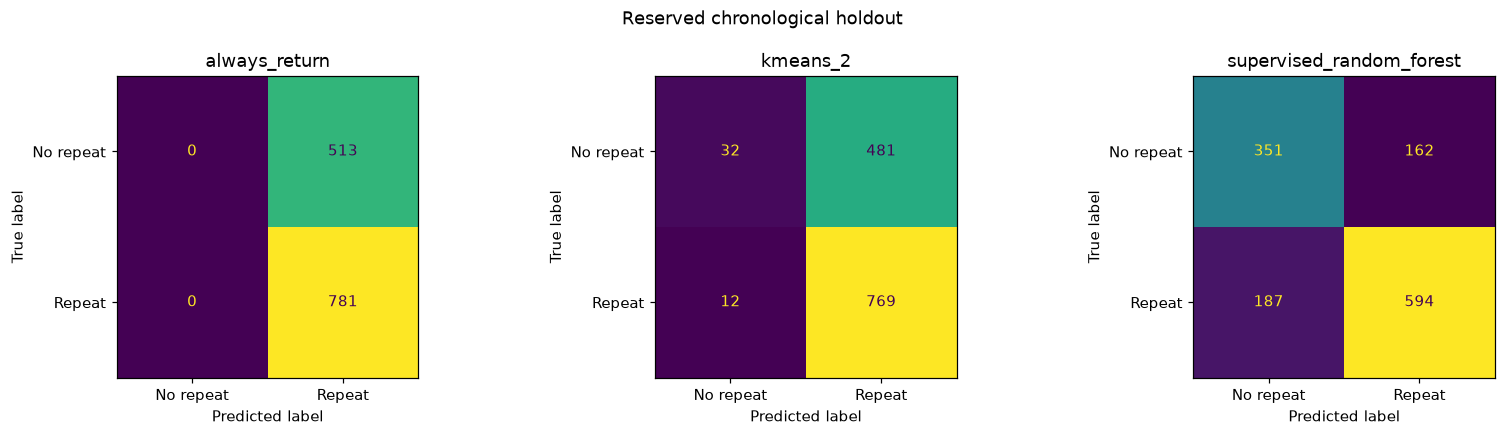

,f1,precision,recall,roc_auc,average_precision
model,,,,,
always_return,0.752771,0.603555,1.000000,0.500000,0.603555
kmeans_2,0.757262,0.615200,0.984635,0.523507,0.615021
supervised_random_forest,0.772934,0.785714,0.760563,0.803810,0.867258


In [5]:
# Final assessment: fitted on development only; the embargoed rows stay excluded.
fitted_models = {}
holdout_results = []
fig, axes = plt.subplots(1, len(models), figsize=(15, 4))
for ax, (name, pipeline) in zip(axes, models.items()):
    fitted = clone(pipeline).fit(X_dev, y_dev)
    fitted_models[name] = fitted
    holdout_results.append({"model": name, **score_model(fitted, X_holdout, y_holdout,
                                                         "classification", settings)})
    predictions = (fitted.predict_proba(X_holdout)[:, 1] >= THRESHOLD).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_holdout, predictions, labels=[0, 1],
                                             display_labels=["No repeat", "Repeat"], ax=ax, colorbar=False)
    ax.set_title(name)
fig.suptitle("Reserved chronological holdout")
fig.tight_layout()
plt.show()
holdout_scores = pd.DataFrame(holdout_results).set_index("model")
display(holdout_scores)

## 4. Profile clusters and visualize development purchases

Use the selected model fitted on development purchases. Cluster profiles report
**training** repeat rates and medians in original business units; these are descriptive,
not independent accuracy measurements. Compare counts alongside rates, since
small clusters have less reliable estimates.

The silhouette score uses preprocessed feature distances, not t-SNE coordinates.
The two plots below share exactly the same t-SNE embedding. Coloring by observed
outcome happens only after embedding. Gaps, apparent islands, axis values, and
relative cluster sizes in t-SNE are not calibrated business quantities or evidence
of predictive accuracy; interpret them alongside temporal validation.

Development silhouette (preprocessed feature space): 0.3081


,purchases,repeat_rate,prior_purchase_count_median,days_since_previous_purchase_median,customer_tenure_days_median,prior_total_spend_median,purchase_count_90d_median,spend_90d_median,Total a Pagar_median
cluster,,,,,,,,,
0,4469,0.575744,10.0,57.0,847.0,6667.9,1.0,331.87,440.96
1,555,0.340541,0.0,NaN,0.0,0.0,0.0,0.00,430.16


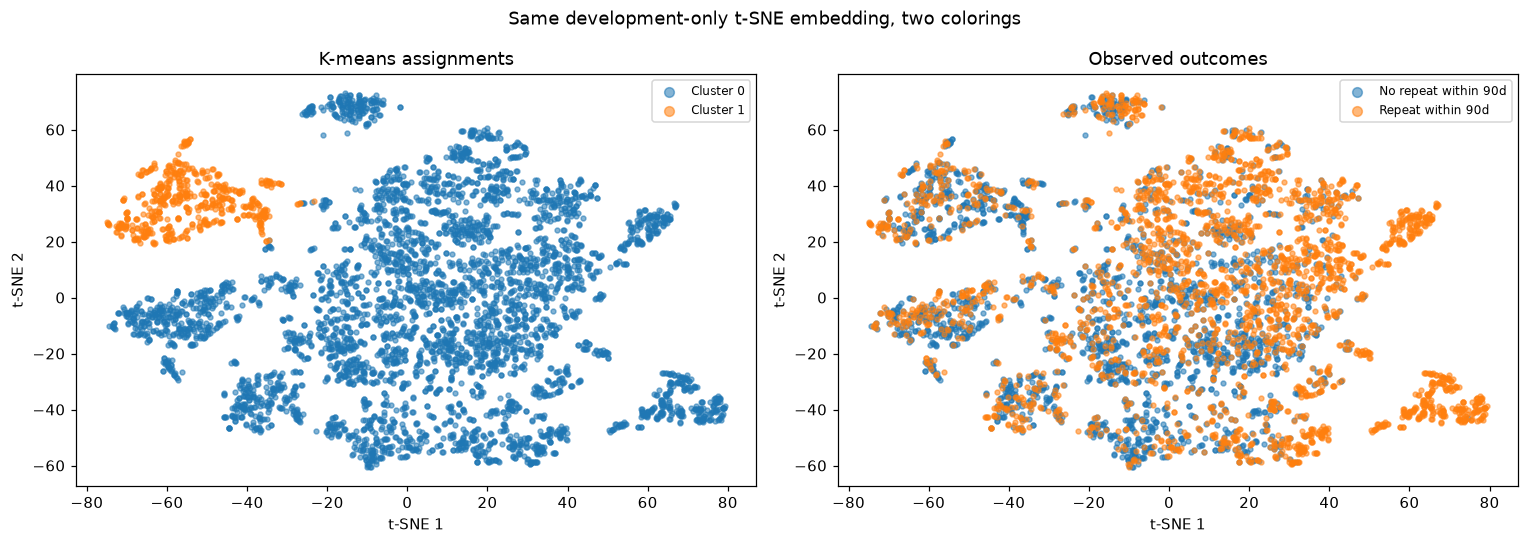

In [6]:
selected = fitted_models[f"kmeans_{best_k}"]
transformed = selected.named_steps["prep"].transform(X_dev)
cluster_model = selected.named_steps["model"]
assignments = cluster_model.kmeans_.predict(transformed)
profile_rows = dev.assign(cluster=assignments)
profile_columns = ["prior_purchase_count", "days_since_previous_purchase",
                   "customer_tenure_days", "prior_total_spend",
                   "purchase_count_90d", "spend_90d", "Total a Pagar"]
profile_columns = [c for c in profile_columns if c in profile_rows.columns]
profiles = profile_rows.groupby("cluster").agg(
    purchases=(config["targets"]["classification"], "size"),
    repeat_rate=(config["targets"]["classification"], "mean"),
)
profiles = profiles.join(profile_rows.groupby("cluster")[profile_columns].median().add_suffix("_median"))
display(profiles)
np.testing.assert_allclose(profiles.repeat_rate.to_numpy(), cluster_model.cluster_rates_[profiles.index])
if 1 < np.unique(assignments).size < len(assignments):
    silhouette = silhouette_score(transformed, assignments)
    print(f"Development silhouette (preprocessed feature space): {silhouette:.4f}")
else:
    silhouette = np.nan
    print("Silhouette undefined: fewer than two populated clusters or one cluster per row.")

assert len(dev) > 30, "Perplexity 30 requires more than 30 development purchases."
embedding = TSNE(n_components=2, init="pca", learning_rate="auto", perplexity=30,
                 max_iter=1000, random_state=SEED).fit_transform(transformed)
assert embedding.shape == (len(dev), 2) and np.isfinite(embedding).all()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for group in np.unique(assignments):
    mask = assignments == group
    axes[0].scatter(embedding[mask, 0], embedding[mask, 1], s=10, alpha=0.55,
                    label=f"Cluster {group}")
for label, title in [(0, "No repeat within 90d"), (1, "Repeat within 90d")]:
    mask = y_dev.to_numpy() == label
    axes[1].scatter(embedding[mask, 0], embedding[mask, 1], s=10, alpha=0.55, label=title)
for ax, title in zip(axes, ["K-means assignments", "Observed outcomes"]):
    ax.set(title=title, xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(markerscale=2, fontsize=8)
fig.suptitle("Same development-only t-SNE embedding, two colorings")
fig.tight_layout()
plt.show()

## 5. Results and business interpretation

The comparison below is generated from this run. Do not revise the cluster count,
preprocessing, or threshold to improve the holdout after seeing these results.
High-repeat clusters may describe frequent or established buyers; lower-repeat
clusters may suggest retention opportunities, but these associations do not establish
that an incentive will change purchasing behavior. The original-unit profiles above
show which history patterns actually characterize each group.

In [7]:
cluster_name = f"kmeans_{best_k}"
supervised_label = f"supervised_{supervised_name}"
cluster_f1 = holdout_scores.loc[cluster_name, "f1"]
floor_f1 = holdout_scores.loc["always_return", "f1"]
supervised_f1 = holdout_scores.loc[supervised_label, "f1"]
print(f"Selected k={best_k}; fixed probability threshold={THRESHOLD}.")
print(f"Holdout F1: clustering {cluster_f1:.4f}, always-return {floor_f1:.4f}, "
      f"{supervised_name} {supervised_f1:.4f}.")
print(f"Clustering F1 difference versus floor: {cluster_f1 - floor_f1:+.4f}; "
      f"versus supervised: {cluster_f1 - supervised_f1:+.4f}.")
if cluster_f1 > floor_f1:
    print("Clustering outperformed the floor on this holdout.")
else:
    print("Clustering did not outperform the floor on this holdout.")
if cluster_f1 > supervised_f1:
    print("Clustering outperformed the configured supervised classifier on this holdout.")
else:
    print("The configured supervised classifier matched or outperformed clustering on this holdout.")
print("These differences are descriptive point estimates, not evidence of statistical significance.")
low, high = profiles.repeat_rate.idxmin(), profiles.repeat_rate.idxmax()
for title, group in [("Lowest", low), ("Highest", high)]:
    print(f"{title} development repeat-rate cluster: {group}, "
          f"rate={profiles.loc[group, 'repeat_rate']:.3f}, "
          f"purchases={int(profiles.loc[group, 'purchases'])}.")
print("No production model, configuration, or submission was replaced.")

Selected k=2; fixed probability threshold=0.5.
Holdout F1: clustering 0.7573, always-return 0.7528, random_forest 0.7729.
Clustering F1 difference versus floor: +0.0045; versus supervised: -0.0157.
Clustering outperformed the floor on this holdout.
The configured supervised classifier matched or outperformed clustering on this holdout.
These differences are descriptive point estimates, not evidence of statistical significance.
Lowest development repeat-rate cluster: 1, rate=0.341, purchases=555.
Highest development repeat-rate cluster: 0, rate=0.576, purchases=4469.
No production model, configuration, or submission was replaced.


## Limitations and references

- Euclidean K-means favors compact groups and is sensitive to feature weighting and outliers.
  One-hot category blocks and correlated history variables can influence distances.
- Training cluster rates are uncalibrated; small groups may have unstable rates.
- Only cluster count was searched. There is no promise clustering improves prediction.
- A single t-SNE run is exploratory and depends on its seed and perplexity. scikit-learn's
  t-SNE does not transform unseen purchases; prediction uses K-means instead.
- Returning customers may appear in both past and future blocks. This evaluates future
  purchase prediction, not generalization exclusively to unseen customers.

Peer-reviewed methodological sources:

1. van der Maaten, L. & Hinton, G. (2008). [Visualizing Data using t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html). *Journal of Machine Learning Research*, 9, 2579–2605.
2. Lloyd, S. (1982). [Least squares quantization in PCM](https://doi.org/10.1109/TIT.1982.1056489). *IEEE Transactions on Information Theory*, 28(2), 129–137.
3. Rousseeuw, P. J. (1987). [Silhouettes: A graphical aid to the interpretation and validation of cluster analysis](https://doi.org/10.1016/0377-0427(87)90125-7). *Journal of Computational and Applied Mathematics*, 20, 53–65.